In [1]:
import numpy as np
import os
os.environ['CUDA_VISIBLE_DEVICES'] = 'GPU-923aa602-92cb-7054-0605-b50ebabdc322'
import torch

from alphagenome.data import genome
from alphagenome.models import dna_client
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.interpretation import ism
from alphagenome.models import dna_client
from alphagenome.models import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.utils import one_hot_encode, characters, random_one_hot
from tangermeme.marginalize import marginalize
from tangermeme.ersatz import substitute
import random
from tqdm import tqdm
import time
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
from tangermeme.io import extract_loci
from tqdm.auto import tqdm
from tangermeme.ablate import ablate
from tangermeme.ersatz import dinucleotide_shuffle
#import seaborn; seaborn.set_style('whitegrid')
import grelu.resources
from utils import create_marginalization_sequence, ablate_motifs, annotate_with_peak_distances
from grelu.visualize import plot_ISM
from grelu.interpret import score

/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/dna_model.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm a

In [2]:
API_KEY = os.environ["ALPHAGENOME_API_KEY"]
dna_model = dna_client.create(API_KEY)

### perform OCT-SOX ablations

In [3]:
motif_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
hits = pd.read_csv(motif_hits, sep='\t')

third_quantile = hits.score.quantile(0.75).item()
second_quantile = hits.score.quantile(0.5).item()
first_quantile = hits.score.quantile(0.25).item()

hits_first = hits[hits.score <= first_quantile]
hits_second = hits[(hits.score > first_quantile) & (hits.score <= second_quantile)]
hits_third = hits[(hits.score > second_quantile) & (hits.score <= third_quantile)]
hits_fourth = hits[hits.score > third_quantile]

hits_first.shape, hits_second.shape, hits_third.shape, hits_fourth.shape

((16882, 10), (17191, 10), (15680, 10), (16420, 10))

In [5]:
scores_first, metadata_first = ablate_motifs(hits_first, dna_model, motif_length = 14, num_loci = 200)
scores_second, metadata_second = ablate_motifs(hits_second, dna_model, motif_length = 14, num_loci = 200)
scores_third, metadata_third = ablate_motifs(hits_third, dna_model, motif_length = 14, num_loci = 200)
scores_fourth, metadata_fourth = ablate_motifs(hits_fourth, dna_model, motif_length = 14, num_loci = 200)

100%|██████████| 200/200 [00:08<00:00, 23.40it/s]


In [6]:
fourth_quantile_color = "#1764ab"
third_quantile_color = "#4a98c9"
second_quantile_color = "#94c4df"
first_quantile_color = "#d0e1f2"


In [7]:
len(scores_first)

305

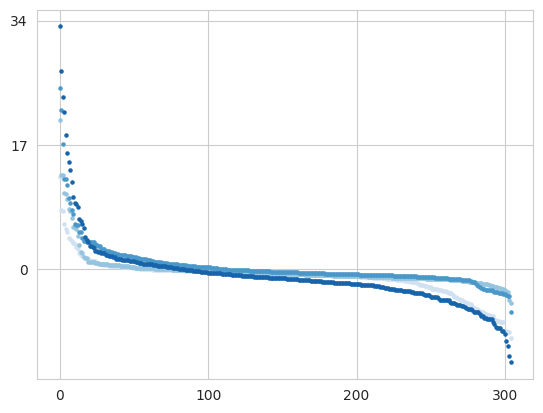

In [8]:
import seaborn as sns
sns.set_style("whitegrid")

sorted_indices = np.argsort(scores_fourth)[::-1]

plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_first)[::-1], color=first_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_second)[::-1], color=second_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_third)[::-1], color=third_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_fourth)[::-1], color=fourth_quantile_color, s=5)

y_min = 0
y_max = max(scores_first.max(), scores_second.max(), scores_third.max(), scores_fourth.max())
y_mid = y_max / 2

plt.yticks([y_min, np.ceil(y_mid), np.ceil(y_max)])
plt.xticks([0, 100, 200, 300])

plt.savefig("octsox_plot.pdf")
plt.savefig("octsox_plot.svg")

### Perform HNF4A ablations

In [9]:
motif_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/HNF4_run_8/fimo.tsv"
hits = pd.read_csv(motif_hits, sep='\t')

third_quantile = hits.score.quantile(0.75).item()
second_quantile = hits.score.quantile(0.5).item()
first_quantile = hits.score.quantile(0.25).item()

hits_first = hits[hits.score <= first_quantile]
hits_second = hits[(hits.score > first_quantile) & (hits.score <= second_quantile)]
hits_third = hits[(hits.score > second_quantile) & (hits.score <= third_quantile)]
hits_fourth = hits[hits.score > third_quantile]

hits_first.shape, hits_second.shape, hits_third.shape, hits_fourth.shape

((237184, 10), (180867, 10), (216341, 10), (194973, 10))

In [10]:
scores_first, metadata_first = ablate_motifs(hits_first, dna_model, motif_length = 14, num_loci = 200)
scores_second, metadata_second = ablate_motifs(hits_second, dna_model, motif_length = 14, num_loci = 200)
scores_third, metadata_third = ablate_motifs(hits_third, dna_model, motif_length = 14, num_loci = 200)
scores_fourth, metadata_fourth = ablate_motifs(hits_fourth, dna_model, motif_length = 14, num_loci = 200)

100%|██████████| 200/200 [00:08<00:00, 23.96it/s]


In [15]:
fourth_quantile_color = "#157f3b"
third_quantile_color = "#4bb062"
second_quantile_color = "#98d594"
first_quantile_color = "#d3eecd"

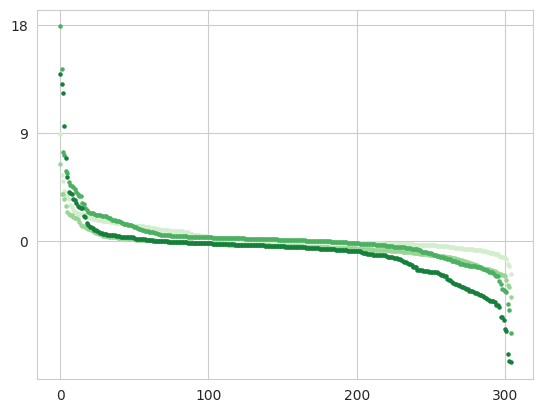

In [16]:
import seaborn as sns
sns.set_style("whitegrid")

sorted_indices = np.argsort(scores_fourth)[::-1]

plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_first)[::-1], color=first_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_second)[::-1], color=second_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_third)[::-1], color=third_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_fourth)[::-1], color=fourth_quantile_color, s=5)

y_min = 0
y_max = max(scores_first.max(), scores_second.max(), scores_third.max(), scores_fourth.max())
y_mid = y_max / 2

plt.yticks([y_min, np.ceil(y_mid), np.ceil(y_max)])
plt.xticks([0, 100, 200, 300])

plt.savefig("HNF4A_plot.pdf")
plt.savefig("HNF4A_plot.svg")

### CTCF ablations

In [29]:
motif_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/CTCF_HITS/fimo.tsv"
hits = pd.read_csv(motif_hits, sep='\t')
hits = hits[hits.sequence_name.astype(str).apply(lambda x: len(x) < 5)]
hits = hits[hits.sequence_name != "hm"]

third_quantile = hits.score.quantile(0.75).item()
second_quantile = hits.score.quantile(0.5).item()
first_quantile = hits.score.quantile(0.25).item()

hits_first = hits[hits.score <= first_quantile]
hits_second = hits[(hits.score > first_quantile) & (hits.score <= second_quantile)]
hits_third = hits[(hits.score > second_quantile) & (hits.score <= third_quantile)]
hits_fourth = hits[hits.score > third_quantile]

hits_first.shape, hits_second.shape, hits_third.shape, hits_fourth.shape

((6470, 10), (6426, 10), (6392, 10), (6406, 10))

In [30]:
scores_first, metadata_first = ablate_motifs(hits_first, dna_model, motif_length = 14, num_loci = 200)
scores_second, metadata_second = ablate_motifs(hits_second, dna_model, motif_length = 14, num_loci = 200)
scores_third, metadata_third = ablate_motifs(hits_third, dna_model, motif_length = 14, num_loci = 200)
scores_fourth, metadata_fourth = ablate_motifs(hits_fourth, dna_model, motif_length = 14, num_loci = 200)

100%|██████████| 200/200 [00:08<00:00, 24.41it/s]


In [31]:
fourth_quantile_color = "#61409b"
third_quantile_color = "#8683bd"
second_quantile_color = "#b6b6d8"
first_quantile_color = "#e2e2ef"



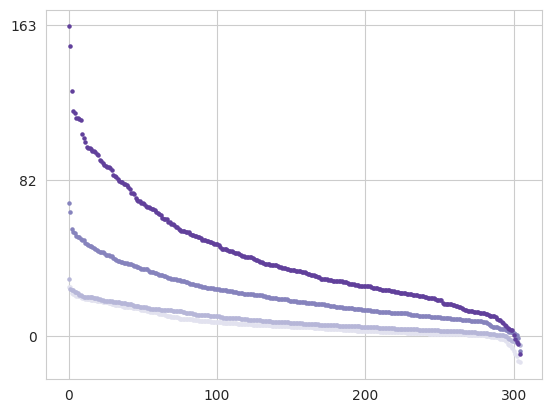

In [32]:
import seaborn as sns
sns.set_style("whitegrid")

sorted_indices = np.argsort(scores_fourth)[::-1]

plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_first)[::-1], color=first_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_second)[::-1], color=second_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_third)[::-1], color=third_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_fourth)[::-1], color=fourth_quantile_color, s=5)

y_min = 0
y_max = max(scores_first.max(), scores_second.max(), scores_third.max(), scores_fourth.max())
y_mid = y_max / 2

plt.yticks([y_min, np.ceil(y_mid), np.ceil(y_max)])
plt.xticks([0, 100, 200, 300])

plt.savefig("CTCF_plot.pdf")
plt.savefig("CTCF_plot.svg")

### AP1 ablations

In [33]:
motif_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/AP1_FIMO_HITS/fimo.tsv"
hits = pd.read_csv(motif_hits, sep='\t')
hits = hits[hits.sequence_name.astype(str).apply(lambda x: len(x) < 5)]
hits = hits[hits.sequence_name != "hm"]

third_quantile = hits.score.quantile(0.75).item()
second_quantile = hits.score.quantile(0.5).item()
first_quantile = hits.score.quantile(0.25).item()

hits_first = hits[hits.score <= first_quantile]
hits_second = hits[(hits.score > first_quantile) & (hits.score <= second_quantile)]
hits_third = hits[(hits.score > second_quantile) & (hits.score <= third_quantile)]
hits_fourth = hits[hits.score > third_quantile]

hits_first.shape, hits_second.shape, hits_third.shape, hits_fourth.shape

((13851, 10), (4479, 10), (9826, 10), (7494, 10))

In [34]:
scores_first, metadata_first = ablate_motifs(hits_first, dna_model, motif_length = 14, num_loci = 200)
scores_second, metadata_second = ablate_motifs(hits_second, dna_model, motif_length = 14, num_loci = 200)
scores_third, metadata_third = ablate_motifs(hits_third, dna_model, motif_length = 14, num_loci = 200)
scores_fourth, metadata_fourth = ablate_motifs(hits_fourth, dna_model, motif_length = 14, num_loci = 200)

100%|██████████| 200/200 [00:08<00:00, 24.44it/s]


In [36]:
fourth_quantile_color = "#bc141a"
third_quantile_color = "#f14432"
second_quantile_color = "#fc8a6a"
first_quantile_color = "#fdcab5"


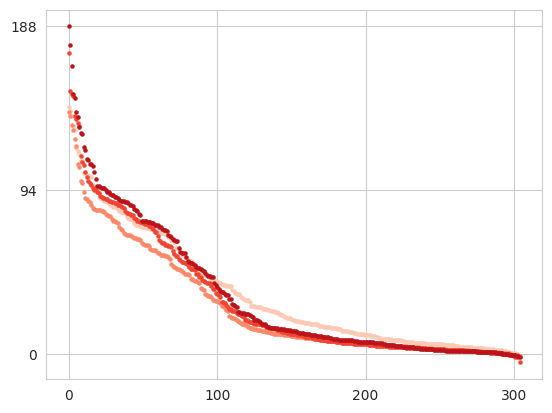

In [37]:
import seaborn as sns
sns.set_style("whitegrid")

sorted_indices = np.argsort(scores_fourth)[::-1]

plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_first)[::-1], color=first_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_second)[::-1], color=second_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_third)[::-1], color=third_quantile_color, s=5)
plt.scatter(np.arange(len(sorted_indices)), np.sort(scores_fourth)[::-1], color=fourth_quantile_color, s=5)

y_min = 0
y_max = max(scores_first.max(), scores_second.max(), scores_third.max(), scores_fourth.max())
y_mid = y_max / 2

plt.yticks([y_min, np.ceil(y_mid), np.ceil(y_max)])
plt.xticks([0, 100, 200, 300])

plt.savefig("AP1_plot.pdf")
plt.savefig("AP1_plot.svg")